In [209]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import kagglehub

from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_curve, precision_score, recall_score, auc, f1_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

ДАТАСЕТ

In [101]:
path = kagglehub.dataset_download("parisrohan/credit-score-classification")
print("Path to dataset files:", path)

Path to dataset files: C:\Users\bvo5\.cache\kagglehub\datasets\parisrohan\credit-score-classification\versions\1


In [102]:
train = pd.read_csv(f'{path}\\train.csv', low_memory=False)
test = pd.read_csv(f'{path}\\test.csv', low_memory=False)

In [103]:
train.head(2)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.82262,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.94496,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good


In [104]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  object 
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  object 
 13  Type_of_Loan              88592 non-null   ob

In [105]:
train.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,84998.000000,100000.000000,100000.00000,100000.000000,100000.000000,98035.000000,100000.000000,100000.000000
mean,4194.170850,17.091280,22.47443,72.466040,21.068780,27.754251,32.285173,1403.118217
std,3183.686167,117.404834,129.05741,466.422621,14.860104,193.177339,5.116875,8306.041270
min,303.645417,-1.000000,0.00000,1.000000,-5.000000,0.000000,20.000000,0.000000
25%,1625.568229,3.000000,4.00000,8.000000,10.000000,3.000000,28.052567,30.306660
50%,3093.745000,6.000000,5.00000,13.000000,18.000000,6.000000,32.305784,69.249473
75%,5957.448333,7.000000,7.00000,20.000000,28.000000,9.000000,36.496663,161.224249
max,15204.633333,1798.000000,1499.00000,5797.000000,67.000000,2597.000000,50.000000,82331.000000


In [106]:
train

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,0x25fe9,CUS_0x942c,April,Nicks,25,078-73-5990,Mechanic,39628.99,3359.415833,4,...,_,502.38,34.663572,31 Years and 6 Months,No,35.104023,60.97133255718485,High_spent_Large_value_payments,479.86622816574095,Poor
99996,0x25fea,CUS_0x942c,May,Nicks,25,078-73-5990,Mechanic,39628.99,3359.415833,4,...,_,502.38,40.565631,31 Years and 7 Months,No,35.104023,54.18595028760385,High_spent_Medium_value_payments,496.651610435322,Poor
99997,0x25feb,CUS_0x942c,June,Nicks,25,078-73-5990,Mechanic,39628.99,3359.415833,4,...,Good,502.38,41.255522,31 Years and 8 Months,No,35.104023,24.02847744864441,High_spent_Large_value_payments,516.8090832742814,Poor
99998,0x25fec,CUS_0x942c,July,Nicks,25,078-73-5990,Mechanic,39628.99,3359.415833,4,...,Good,502.38,33.638208,31 Years and 9 Months,No,35.104023,251.67258219721603,Low_spent_Large_value_payments,319.1649785257098,Standard


In [107]:
#Функция для обработки фичи Credit_History_Age, переводит строку в интепретируеморе число
def Credit_History_Age(s=str):
    try:
        y, m = map(int, s[:s.rfind(' ')].split(" Years and "))
        return y + m/12
    except:
        return s

In [108]:
#Дропаем колонки, не связанные с целевой переменной 
train = train.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN'])
test = test.drop(columns=['ID', 'Customer_ID', 'Name', 'SSN'])
#Меняем Credit_History_Age
train["Credit_History_Age"] = train["Credit_History_Age"].apply(lambda s: Credit_History_Age(s))
test["Credit_History_Age"] = test["Credit_History_Age"].apply(lambda s: Credit_History_Age(s))

In [109]:
train.head(2)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,January,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,_,809.98,26.82262,22.083333,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,February,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,Good,809.98,31.94496,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good


In [110]:
#Выделяем категориальные признаки
cat_features = ["Month", "Occupation", "Type_of_Loan", "Credit_Mix", "Payment_Behaviour", "Payment_of_Min_Amount"]

In [111]:
# приведение артефактных значений к NaN
def drop_artifact_rows(df, columns):
    """
    Удаляет строки, в которых в указанных колонках содержатся нечисловые значения (артефакты).
    Пропуски (NaN) игнорируются и остаются в данных.
    """
    mask = pd.Series(False, index=df.index)
    
    for col in columns:
        # Пытаемся конвертировать в числа. Артефакты станут NaN.
        converted = pd.to_numeric(df[col], errors='coerce')
        
        # Находим строки, которые БЫЛИ не NaN, но СТАЛИ NaN после конвертации.
        # Это и есть наши артефакты.
        artifacts = df[col].notna() & converted.isna()
        
        # Добавляем найденные строки в общую маску для удаления
        mask = mask | artifacts
        
        print(f"В колонке '{col}' найдено артефактов: {artifacts.sum()}")

    # Возвращаем датафрейм без этих строк
    df_cleaned = df[~mask].copy()
    
    # Принудительно меняем тип колонок на числовой для тех, что очистили
    for col in columns:
        df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='ignore')
        
    return df_cleaned


In [112]:
for col in train.drop(columns = cat_features).columns:
    try:
        train[col].astype(float)
    except ValueError:
        print(f"Ошибка в столбце: {col}")

Ошибка в столбце: Age
Ошибка в столбце: Annual_Income
Ошибка в столбце: Num_of_Loan
Ошибка в столбце: Num_of_Delayed_Payment
Ошибка в столбце: Changed_Credit_Limit
Ошибка в столбце: Outstanding_Debt
Ошибка в столбце: Amount_invested_monthly
Ошибка в столбце: Monthly_Balance
Ошибка в столбце: Credit_Score


In [113]:
train = drop_artifact_rows(train, ["Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance"])
test = drop_artifact_rows(test, ["Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment", "Changed_Credit_Limit", "Outstanding_Debt", "Amount_invested_monthly", "Monthly_Balance"])

В колонке 'Age' найдено артефактов: 4939
В колонке 'Annual_Income' найдено артефактов: 6980
В колонке 'Num_of_Loan' найдено артефактов: 4785
В колонке 'Num_of_Delayed_Payment' найдено артефактов: 2744
В колонке 'Changed_Credit_Limit' найдено артефактов: 2091
В колонке 'Outstanding_Debt' найдено артефактов: 1009
В колонке 'Amount_invested_monthly' найдено артефактов: 4305
В колонке 'Monthly_Balance' найдено артефактов: 9
В колонке 'Age' найдено артефактов: 2477


C:\Users\bvo5\AppData\Local\Temp\ipykernel_11604\1194706066.py:27: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='ignore')


В колонке 'Annual_Income' найдено артефактов: 3520
В колонке 'Num_of_Loan' найдено артефактов: 2436
В колонке 'Num_of_Delayed_Payment' найдено артефактов: 1427
В колонке 'Changed_Credit_Limit' найдено артефактов: 1059
В колонке 'Outstanding_Debt' найдено артефактов: 491
В колонке 'Amount_invested_monthly' найдено артефактов: 2175
В колонке 'Monthly_Balance' найдено артефактов: 6


In [114]:
# Превращаем всё в string. NaN станут строками 'nan'
for col in cat_features:
    train[col] = train[col].astype(str)
    test[col] = test[col].astype(str)

In [115]:
test.head(1)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,September,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,2022.0,Good,809.98,35.030402,22.75,No,49.574949,236.642682,Low_spent_Small_value_payments,186.266702


In [116]:
y, X = train['Credit_Score'], train.drop('Credit_Score', axis=1) 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [151]:
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))

In [169]:
model = CatBoostClassifier(
    iterations=200,
    learning_rate=0.1,
    depth=7,
    class_weights=class_weights,
    cat_features=cat_features,
    verbose=10 # Показывать лог каждые 10 итераций
)

In [171]:
train_data = Pool(
    data=X_train, 
    label=y_train, 
    cat_features=cat_features
)

model.fit(train_data)

0:	learn: 1.0335765	total: 98.9ms	remaining: 19.7s
10:	learn: 0.7486589	total: 1.11s	remaining: 19.1s
20:	learn: 0.6535151	total: 2.09s	remaining: 17.8s
30:	learn: 0.6159015	total: 3.08s	remaining: 16.8s
40:	learn: 0.5955557	total: 4.05s	remaining: 15.7s
50:	learn: 0.5828685	total: 5s	remaining: 14.6s
60:	learn: 0.5733196	total: 5.93s	remaining: 13.5s
70:	learn: 0.5671408	total: 6.95s	remaining: 12.6s
80:	learn: 0.5611205	total: 7.89s	remaining: 11.6s
90:	learn: 0.5563706	total: 8.86s	remaining: 10.6s
100:	learn: 0.5521343	total: 9.75s	remaining: 9.56s
110:	learn: 0.5482350	total: 10.7s	remaining: 8.58s
120:	learn: 0.5429222	total: 11.7s	remaining: 7.65s
130:	learn: 0.5388150	total: 12.7s	remaining: 6.7s
140:	learn: 0.5351613	total: 13.7s	remaining: 5.73s
150:	learn: 0.5307127	total: 14.7s	remaining: 4.75s
160:	learn: 0.5273426	total: 15.6s	remaining: 3.77s
170:	learn: 0.5243599	total: 16.6s	remaining: 2.81s
180:	learn: 0.5211952	total: 17.5s	remaining: 1.84s
190:	learn: 0.5190454	tota

In [175]:
# Жесткие предсказания (0, 1 или 2)
y_pred = model.predict(X_test)

# Вероятности (вернет матрицу n_samples x 3)
y_proba = model.predict_proba(X_test)

In [177]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nОтчет по классификации:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7752520260921131

Отчет по классификации:
              precision    recall  f1-score   support

        Good       0.60      0.91      0.72      2656
        Poor       0.76      0.86      0.81      4417
    Standard       0.91      0.68      0.78      8104

    accuracy                           0.78     15177
   macro avg       0.75      0.82      0.77     15177
weighted avg       0.81      0.78      0.78     15177



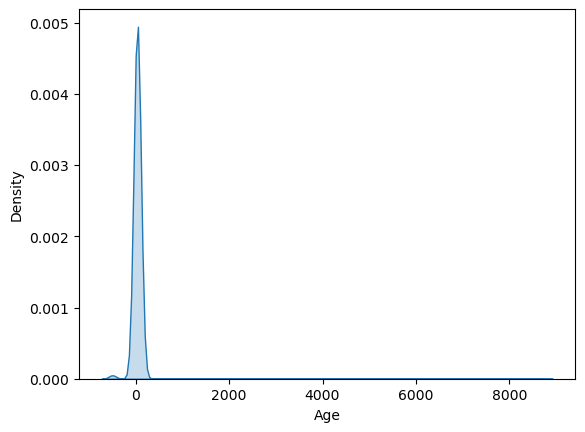

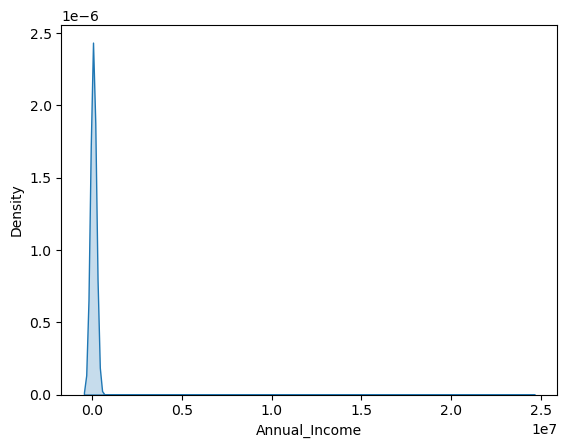

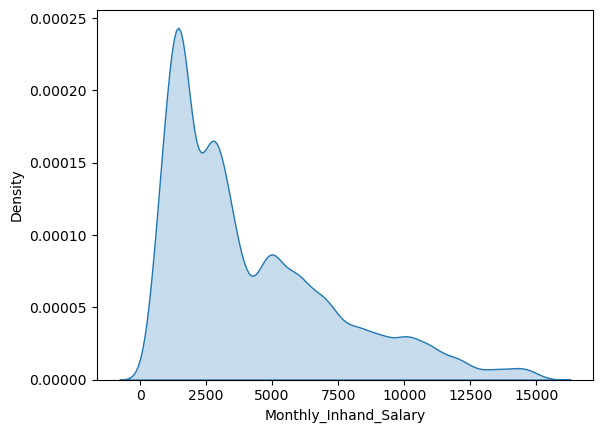

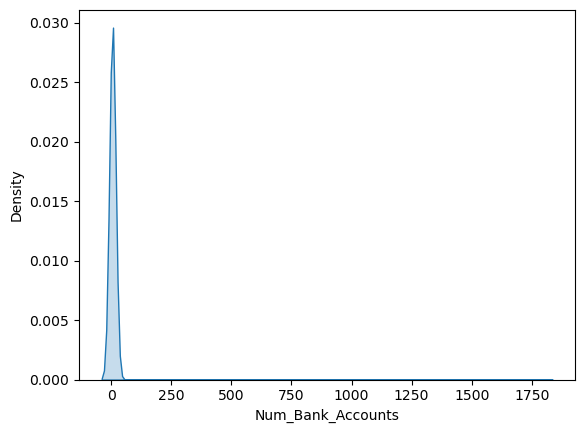

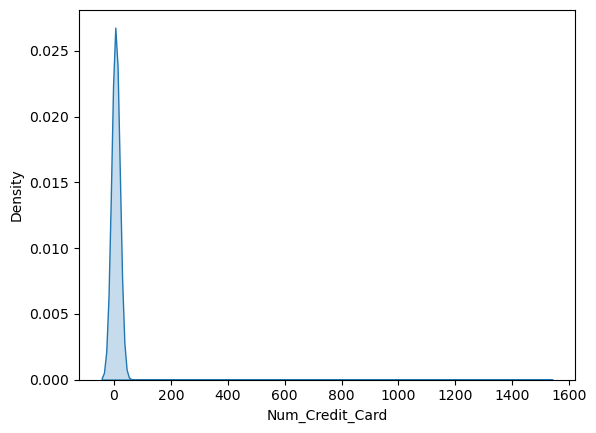

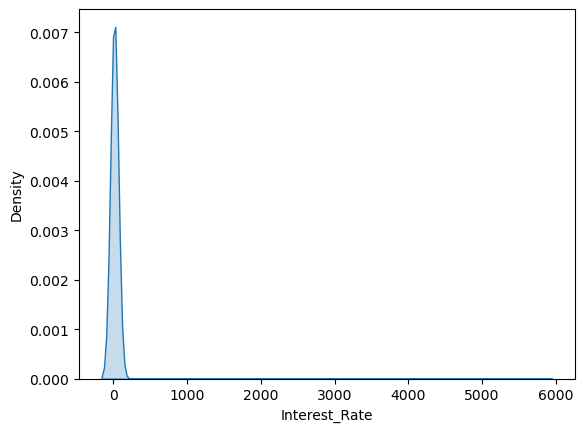

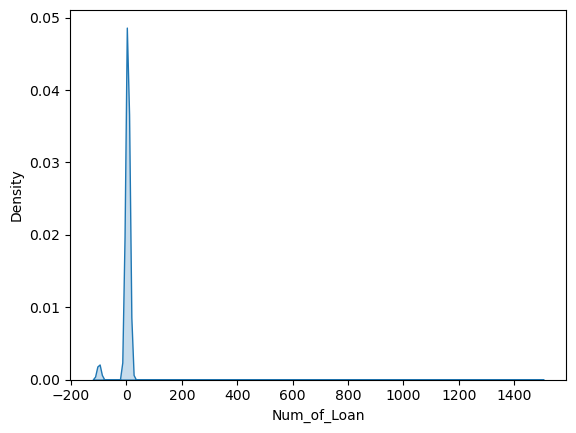

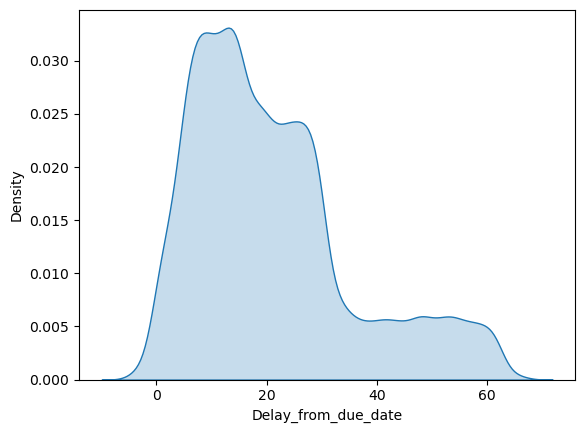

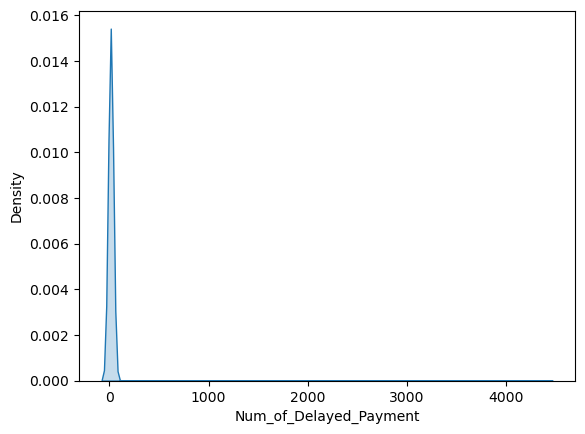

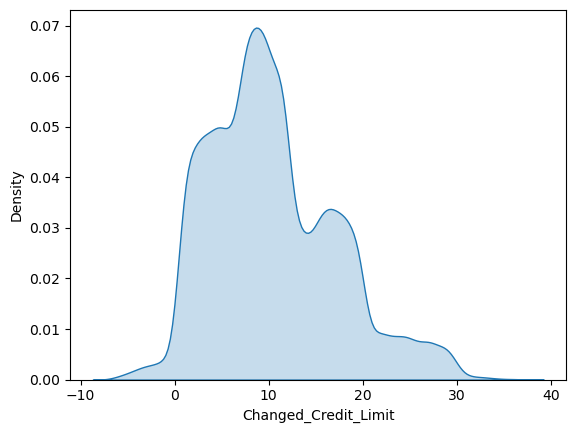

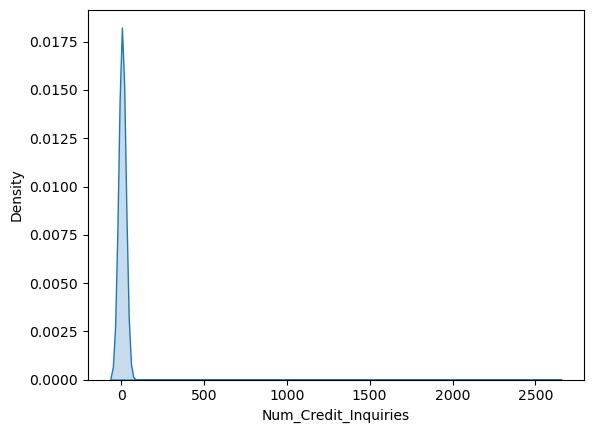

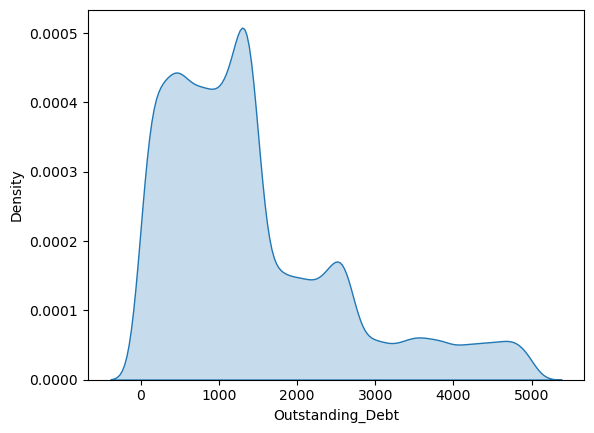

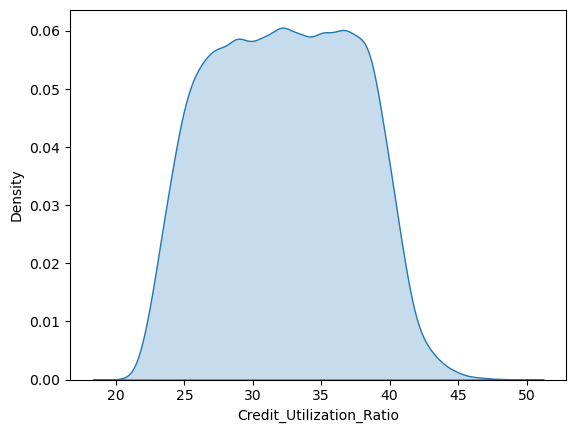

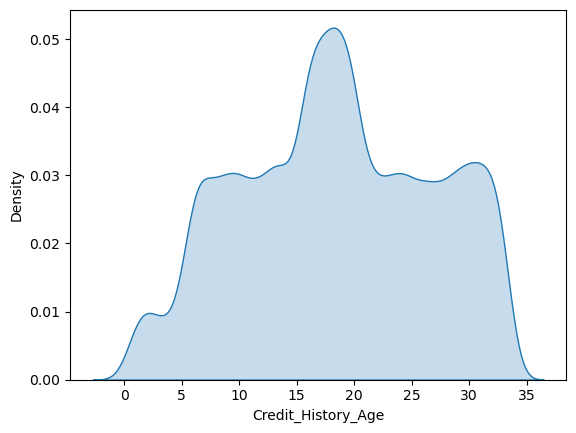

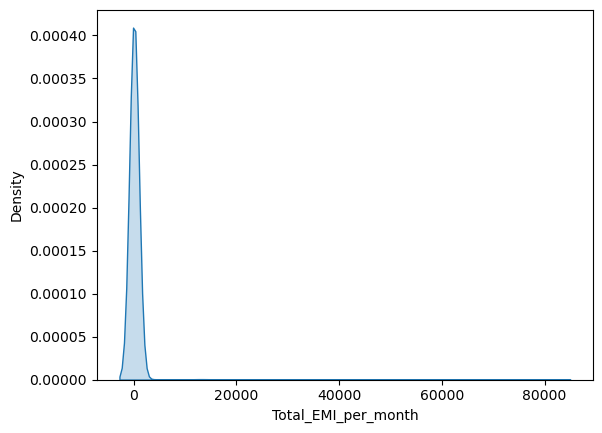

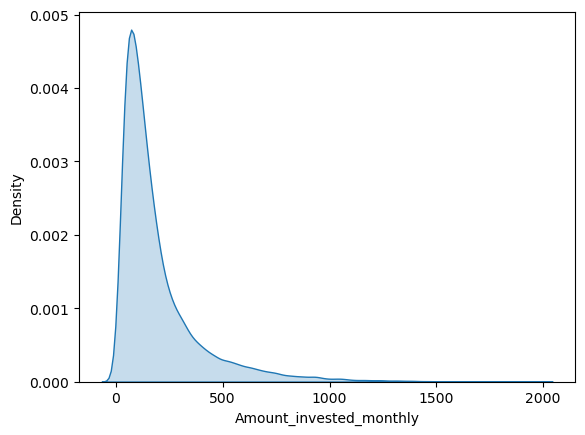

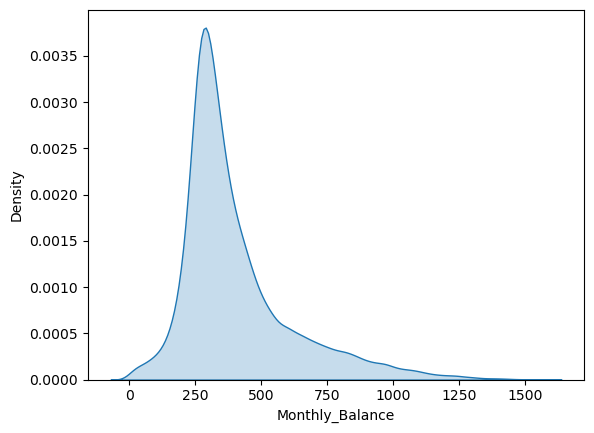

In [195]:
for col in X_train.drop(columns = cat_features).columns:
    sns.kdeplot(X_train[col], fill=True)
    plt.show()

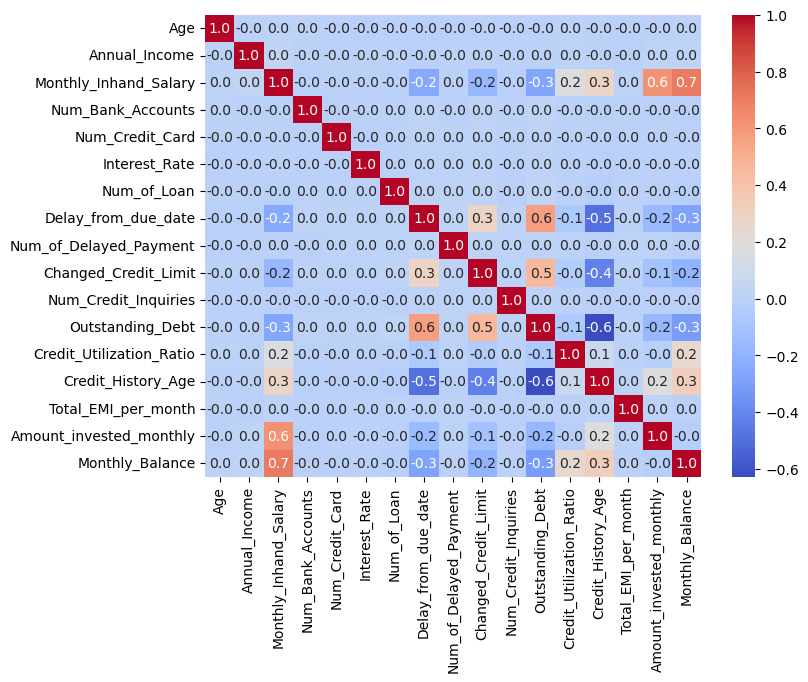

In [207]:
corr = X_train.drop(columns = cat_features).corr()
# Plot the heatmap
plt.figure(figsize=(8, 6)) # Optional: Adjust figure size
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt=".1f")
plt.show()